In [108]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Added missing imports for the preprocessing pipeline
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [110]:
df = pd.read_csv('/content/drive/MyDrive/PrEP Ever (9).csv')

In [111]:
df.head()

,mflCode,FacilityName,patient_id,Gender,DOB,national_id_no,PREP_Number,population_type,key_population_type,enrollment_date,...,regimen_prescribed,months_prescribed_regimen,condoms_issued,number_of_condoms,appointment_given,appointment_date,reason_no_appointment,date_discontinued,last_prep_dose_date,discontinue_reason
0,19271,Swop Korogocho,828,F,24/09/1986,NaN,1.927120e+13,Key Population,Female sex worker,02/06/2021,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,19271,Swop Korogocho,833,M,10/09/1992,25231874.0,1.927120e+13,Key Population,NaN,05/08/2021,...,TDF/FTC,1.0,Yes,NaN,Yes,02/09/2021,NaN,NaN,NaN,NaN
2,19271,Swop Korogocho,834,F,28/12/1994,33226012.0,1.927120e+13,Key Population,NaN,05/08/2021,...,TDF/FTC,1.0,Yes,20.0,Yes,26/09/2024,NaN,NaN,NaN,NaN
3,19271,Swop Korogocho,835,F,12/12/1981,NaN,1.927120e+13,Key Population,NaN,05/08/2021,...,TDF/3TC,1.0,Yes,144.0,Yes,19/08/2021,NaN,NaN,NaN,NaN
4,19271,Swop Korogocho,842,F,07/07/1986,26768457.0,1.927120e+13,Key Population,NaN,02/09/2021,...,TDF/3TC,1.0,Yes,144.0,Yes,23/09/2021,NaN,NaN,NaN,NaN


In [112]:
df.tail()

,mflCode,FacilityName,patient_id,Gender,DOB,national_id_no,PREP_Number,population_type,key_population_type,enrollment_date,...,regimen_prescribed,months_prescribed_regimen,condoms_issued,number_of_condoms,appointment_given,appointment_date,reason_no_appointment,date_discontinued,last_prep_dose_date,discontinue_reason
1550,19271,Swop Korogocho,12988,F,06/06/1998,NaN,1.927120e+13,Key Population,Female sex worker,20/08/2026,...,TDF/FTC,1.0,Yes,NaN,Yes,NaN,NaN,NaN,NaN,NaN
1551,19271,Swop Korogocho,5313,F,08/11/1987,25896977.0,1.927120e+13,Key Population,Female sex worker,26/08/2026,...,TDF/FTC,1.0,NaN,NaN,Yes,28/09/2026,NaN,NaN,NaN,NaN
1552,19271,Swop Korogocho,5536,F,05/04/1980,NaN,1.927120e+13,Key Population,Female sex worker,01/09/2026,...,TDF/FTC,1.0,Yes,5.0,Yes,NaN,NaN,NaN,NaN,NaN
1553,19271,Swop Korogocho,12799,F,01/01/1989,NaN,1.927120e+13,Key Population,Female sex worker,13/08/2026,...,TDF/FTC,1.0,Yes,NaN,Yes,NaN,NaN,NaN,NaN,NaN
1554,19271,Swop Korogocho,13029,F,01/06/1982,NaN,1.927120e+13,Key Population,Female sex worker,01/09/2026,...,TDF/FTC,1.0,NaN,NaN,Yes,01/10/2026,NaN,NaN,NaN,NaN


In [113]:
print(df.columns.tolist())

['mflCode', 'FacilityName', 'patient_id', 'Gender', 'DOB', 'national_id_no', 'PREP_Number', 'population_type', 'key_population_type', 'enrollment_date', 'patient_type', 'referral_entry_point', 'form', 'latest_prep_visit_date', 'sti_screened', 'genital_ulcer_disease', 'vaginal_discharge', 'cervical_discharge', 'pid', 'anal_discharge', 'urethral_discharge', 'other_sti_symptoms', 'sti_screened.1', 'vmmc_screened', 'vmmc_status', 'vmmc_referred', 'lmp', 'menopausal_status', 'pregnant', 'edd', 'planned_pregnancy', 'wanted_pregnancy', 'breastfeeding', 'fp_status', 'fp_method', 'ended_pregnancy', 'pregnancy_outcome', 'outcome_date', 'defects', 'has_chronic_illness', 'adverse_reactions', 'known_allergies', 'hepatitisB_vaccinated', 'hepatitisB_treated', 'hepatitisC_vaccinated', 'hepatitisC_treated', 'hiv_signs', 'adherence_counselled', 'adherence_outcome', 'poor_adherence_reasons', 'other_poor_adherence_reasons', 'prep_contraindications', 'treatment_plan', 'switching_option', 'switching_date', 

In [114]:
# Examine the variables related to PrEP adherence

adherence_columns = [
    'adherence_counselled',
    'adherence_outcome',
    'poor_adherence_reasons',
    'other_poor_adherence_reasons',
    'treatment_plan',
    'switching_option',
    'prep_type',
    'months_prescribed_regimen',
    'appointment_given',
    'reason_no_appointment',
    'date_discontinued',
    'last_prep_dose_date',
    'discontinue_reason',
    'latest_prep_visit_date'
]

for col in adherence_columns:
    if col in df.columns:
        print("\n" + "="*60)
        print(col)
        print("="*60)
        print(df[col].value_counts(dropna=False).head(30))
    else:
        print("\n" + "="*60)
        print(f"{col} (Column has been dropped or does not exist)")
        print("="*60)


adherence_counselled
adherence_counselled
Yes    1183
NaN     202
No      170
Name: count, dtype: int64

adherence_outcome
adherence_outcome
NaN     1375
Good     161
Fair      18
Poor       1
Name: count, dtype: int64

poor_adherence_reasons
poor_adherence_reasons
NaN                   1470
No perceived risk       39
Lost/out of pills       29
Stigma                   6
Forgot                   6
Pill burden              3
Shared with others       2
Name: count, dtype: int64

other_poor_adherence_reasons
other_poor_adherence_reasons
NaN                              1552
SYPHILLIS                           1
partner of unknown hiv status       1
candidiasis                         1
Name: count, dtype: int64

treatment_plan
treatment_plan
Start          722
Continue       312
Restart        306
NaN            206
Discontinue      9
Name: count, dtype: int64

switching_option
switching_option
NaN    1555
Name: count, dtype: int64

prep_type
prep_type
Daily Oral PrEP    867
NaN         

In [115]:
#Drop completely empty columns
empty_cols = df.columns[df.isnull().sum() == len(df)]
df_clean = df.drop(columns=empty_cols).copy()

In [116]:
#Drop identifiers and facility-identifying columns
columns_to_drop = [
    'patient_id',
    'national_id',
    'facility_name',
    'mfl_code'
]

In [117]:

#Process dates and derive patient age at enrollment
df_clean["DOB_dt"] = pd.to_datetime(
    df_clean["DOB"], format="%d/%m/%Y", errors="coerce"
)
df_clean["enrollment_dt"] = pd.to_datetime(
    df_clean["enrollment_date"], format="%d/%m/%Y", errors="coerce"
)

In [118]:
# Compute age in years
df_clean["age"] = (
    df_clean["enrollment_dt"] - df_clean["DOB_dt"]
).dt.days / 365.25

In [119]:
#Impute median age for missing values
median_age = df_clean["age"].median()
df_clean["age"] = df_clean["age"].fillna(median_age)

In [120]:
df_clean['age'].describe()

,age
count,1555.000000
mean,31.931561
std,8.522378
min,16.616016
25%,25.111567
50%,30.778919
75%,37.817933
max,67.321013


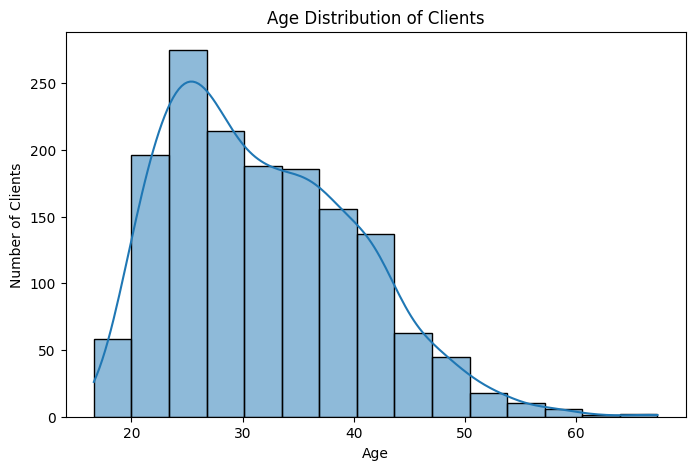

In [121]:
plt.figure(figsize=(8, 5))

sns.histplot(df_clean["age"].dropna(), bins=15, kde=True)

plt.title("Age Distribution of Clients")
plt.xlabel("Age")
plt.ylabel("Number of Clients")

plt.show()

Create age groups

This will help with exploratory analysis.

In [122]:
df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[0, 19, 24, 29, 34, 39, 49, 100],
    labels=[
        "≤19",
        "20-24",
        "25-29",
        "30-34",
        "35-39",
        "40-49",
        "50+"
    ]
)

In [123]:
# Ensure 'adherence_status' is present in df_clean before generating crosstab
if 'adherence_status' not in df_clean.columns:
    df_clean['adherence_status'] = df_clean['adherence_outcome'].map({
        'Good': 0,
        'Fair': 1,
        'Poor': 1
    })

pd.crosstab(
    df_clean['age_group'],
    df_clean["adherence_status"],
    normalize="index"
) * 100

adherence_status,0.0,1.0
age_group,,
≤19,60.000000,40.000000
20-24,91.836735,8.163265
25-29,88.000000,12.000000
30-34,88.000000,12.000000
35-39,89.655172,10.344828
40-49,95.000000,5.000000
50+,100.000000,0.000000


Create the STI variable

Your STI information is spread across several columns.

In [124]:
sti_cols = [
    "sti_screened",
    "sti_screened.1",
    "genital_ulcer_disease",
    "vaginal_discharge",
    "cervical_discharge",
    "pid",
    "anal_discharge",
    "other_sti_symptoms"
]

In [125]:
def create_sti_status(row):

    values = []

    for col in sti_cols:
        if col in row.index and pd.notna(row[col]):
            values.append(str(row[col]).strip().lower())

    positive_values = [
        "yes",
        "positive",
        "present",
        "1",
        "true"
    ]

    if any(value in positive_values for value in values):
        return 1

    if len(values) == 0:
        return np.nan

    return 0

In [126]:
df["sti_present"] = df.apply(
    create_sti_status,
    axis=1
)

In [127]:
# Shape of the dfset
print("dfset shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# df types
print("\ndf types:")
print(df.dtypes)

dfset shape: (1555, 68)

Columns:
['mflCode', 'FacilityName', 'patient_id', 'Gender', 'DOB', 'national_id_no', 'PREP_Number', 'population_type', 'key_population_type', 'enrollment_date', 'patient_type', 'referral_entry_point', 'form', 'latest_prep_visit_date', 'sti_screened', 'genital_ulcer_disease', 'vaginal_discharge', 'cervical_discharge', 'pid', 'anal_discharge', 'urethral_discharge', 'other_sti_symptoms', 'sti_screened.1', 'vmmc_screened', 'vmmc_status', 'vmmc_referred', 'lmp', 'menopausal_status', 'pregnant', 'edd', 'planned_pregnancy', 'wanted_pregnancy', 'breastfeeding', 'fp_status', 'fp_method', 'ended_pregnancy', 'pregnancy_outcome', 'outcome_date', 'defects', 'has_chronic_illness', 'adverse_reactions', 'known_allergies', 'hepatitisB_vaccinated', 'hepatitisB_treated', 'hepatitisC_vaccinated', 'hepatitisC_treated', 'hiv_signs', 'adherence_counselled', 'adherence_outcome', 'poor_adherence_reasons', 'other_poor_adherence_reasons', 'prep_contraindications', 'treatment_plan', 'swi

In [128]:
df["sti_present"].value_counts(dropna=False)

,count
sti_present,
1.0,1271
NaN,202
0.0,82


In [129]:
print(df["adherence_outcome"].value_counts(dropna=False))

adherence_outcome
NaN     1375
Good     161
Fair      18
Poor       1
Name: count, dtype: int64


In [130]:
adherence_columns = [
    col for col in df.columns
    if any(word in col.lower() for word in [
        'adher', 'outcome', 'miss', 'pickup', 'pick', 'refill',
        'appointment', 'return', 'discontinue', 'stop'
    ])
]

print(adherence_columns)

['pregnancy_outcome', 'outcome_date', 'adherence_counselled', 'adherence_outcome', 'poor_adherence_reasons', 'other_poor_adherence_reasons', 'appointment_given', 'appointment_date', 'reason_no_appointment', 'date_discontinued', 'discontinue_reason']


In [131]:
# Create binary adherence status
df['adherence_status'] = df['adherence_outcome'].map({
    'Good': 0,
    'Fair': 1,
    'Poor': 1
})

# Check the result
print(df['adherence_status'].value_counts(dropna=False))

adherence_status
NaN    1375
0.0     161
1.0      19
Name: count, dtype: int64


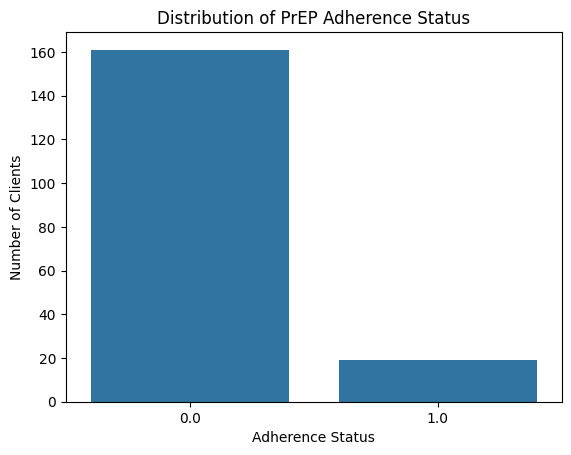

In [132]:
sns.countplot(x="adherence_status", data=df)

plt.title("Distribution of PrEP Adherence Status")
plt.xlabel("Adherence Status")
plt.ylabel("Number of Clients")

plt.show()

#Check adherence outcome

In [133]:
# Check adherence outcome counts
print(df["adherence_outcome"].value_counts(dropna=False))

# Check numerical adherence status
print("\nAdherence status:")
print(df["adherence_status"].value_counts(dropna=False))

adherence_outcome
NaN     1375
Good     161
Fair      18
Poor       1
Name: count, dtype: int64

Adherence status:
adherence_status
NaN    1375
0.0     161
1.0      19
Name: count, dtype: int64


Remove records without an outcome

This is important. We cannot train a supervised df on people whose adherence outcome is unknown.

In [134]:
# Keep only records with a known adherence outcome
df_df = df.dropna(subset=["adherence_status"]).copy()

print("Original records:", len(df))
print("Records with known adherence:", len(df_df))
print("Records removed:", len(df) - len(df_df))

Original records: 1555
Records with known adherence: 180
Records removed: 1375


Check the class distribution

In [135]:
print("\nAdherence class distribution:")
print(df_df["adherence_status"].value_counts())

print("\nAdherence percentages:")
print(
    df_df["adherence_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Adherence class distribution:
adherence_status
0.0    161
1.0     19
Name: count, dtype: int64

Adherence percentages:
adherence_status
0.0    89.44
1.0    10.56
Name: proportion, dtype: float64


In [136]:
# Target variable
y = df_df["adherence_status"].astype(int)

print("Target variable:")
print(y.value_counts())

Target variable:
adherence_status
0    161
1     19
Name: count, dtype: int64


In [137]:
features = [
    "DOB",
    "Gender",
    "key_population_type",
    "patient_type",
    "prep_type",
    "regimen_prescribed",
    "condoms_issued",
    "number_of_condoms",
    "pregnant",
    "planned_pregnancy",
    "wanted_pregnancy",
    "breastfeeding",
    "fp_status",
    "has_chronic_illness",
    "adverse_reactions",
    "known_allergies",
    "hepatitisB_vaccinated",
    "hepatitisB_treated",
    "hepatitisC_vaccinated",
    "hepatitisC_treated",
    "adherence_counselled",
    "appointment_given"
]

X = df_df[features].copy()

print("Predictor shape:", X.shape)
X.head()

Predictor shape: (180, 22)


,DOB,Gender,key_population_type,patient_type,prep_type,regimen_prescribed,condoms_issued,number_of_condoms,pregnant,planned_pregnancy,...,fp_status,has_chronic_illness,adverse_reactions,known_allergies,hepatitisB_vaccinated,hepatitisB_treated,hepatitisC_vaccinated,hepatitisC_treated,adherence_counselled,appointment_given
2,28/12/1994,F,NaN,New Patient,Daily Oral PrEP,TDF/FTC,Yes,20.0,No,NaN,...,On Family Planning,No,2.0,2.0,No,No,No,No,Yes,Yes
9,15/06/1994,F,NaN,New Patient,Daily Oral PrEP,TDF/FTC,Yes,15.0,No,NaN,...,On Family Planning,No,2.0,2.0,No,No,No,No,Yes,Yes
17,19/10/1993,F,NaN,New Patient,Daily Oral PrEP,TDF/FTC,Yes,10.0,No,NaN,...,On Family Planning,No,2.0,2.0,NaN,NaN,NaN,NaN,Yes,Yes
20,15/06/1990,F,NaN,New Patient,Daily Oral PrEP,TDF/FTC,Yes,20.0,No,NaN,...,On Family Planning,No,2.0,2.0,NaN,NaN,NaN,NaN,Yes,Yes
48,31/07/2000,F,Female sex worker,New Patient,Daily Oral PrEP,TDF/FTC,Yes,10.0,No,NaN,...,On Family Planning,No,2.0,2.0,NaN,NaN,NaN,NaN,Yes,Yes


Inspect missing values


In [138]:
missing = pd.DataFrame({
    "Missing_Count": X.isna().sum(),
    "Missing_Percentage": (X.isna().mean() * 100).round(2)
})

missing = missing.sort_values(
    "Missing_Percentage",
    ascending=False
)

missing

,Missing_Count,Missing_Percentage
planned_pregnancy,179,99.44
hepatitisC_treated,117,65.00
hepatitisB_treated,117,65.00
hepatitisB_vaccinated,117,65.00
hepatitisC_vaccinated,117,65.00
wanted_pregnancy,33,18.33
breastfeeding,32,17.78
fp_status,31,17.22
key_population_type,28,15.56
pregnant,24,13.33


Check the unique values of categorical variables

In [139]:
categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(X[col].value_counts(dropna=False).head(15))


--- DOB ---
DOB
31/07/2000    2
07/07/1996    2
28/08/1993    2
22/09/1986    2
31/12/1987    2
19/10/1993    1
15/06/1990    1
23/01/2004    1
21/04/1997    1
01/02/1987    1
01/01/1987    1
18/11/1989    1
07/10/1997    1
15/06/1994    1
28/12/1994    1
Name: count, dtype: int64

--- Gender ---
Gender
F    175
M      5
Name: count, dtype: int64

--- key_population_type ---
key_population_type
Female sex worker            147
NaN                           28
Men who have sex with men      3
165084                         2
Name: count, dtype: int64

--- patient_type ---
patient_type
New Patient    166
Restart         13
Transfer in      1
Name: count, dtype: int64

--- prep_type ---
prep_type
Daily Oral PrEP    153
NaN                 23
Event Driven         4
Name: count, dtype: int64

--- regimen_prescribed ---
regimen_prescribed
TDF/FTC    174
NaN          5
TDF          1
Name: count, dtype: int64

--- condoms_issued ---
condoms_issued
Yes    176
NaN      3
No       1
Name: count

Check numerical variables

In [140]:
numeric_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns

X[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
number_of_condoms,158.0,18.753165,18.999057,1.0,10.0,15.0,20.0,144.0
adverse_reactions,180.0,2.000000,0.000000,2.0,2.0,2.0,2.0,2.0
known_allergies,180.0,2.000000,0.000000,2.0,2.0,2.0,2.0,2.0


In [141]:
# Define numeric features
numeric_features = ['number_of_condoms', 'adverse_reactions', 'known_allergies']

# Define categorical features (DOB removed)
categorical_features = [
    'Gender',
    'key_population_type',
    'patient_type',
    'prep_type',
    'regimen_prescribed',
    'condoms_issued',
    'pregnant',
    'planned_pregnancy',
    'wanted_pregnancy',
    'breastfeeding',
    'fp_status',
    'has_chronic_illness',
    'hepatitisB_vaccinated',
    'hepatitisB_treated',
    'hepatitisC_vaccinated',
    'hepatitisC_treated',
    'adherence_counselled',
    'appointment_given'
]

print(f"Numeric features ({len(numeric_features)}):", numeric_features)
print(f"Categorical features ({len(categorical_features)}):", categorical_features)

Numeric features (3): ['number_of_condoms', 'adverse_reactions', 'known_allergies']
Categorical features (18): ['Gender', 'key_population_type', 'patient_type', 'prep_type', 'regimen_prescribed', 'condoms_issued', 'pregnant', 'planned_pregnancy', 'wanted_pregnancy', 'breastfeeding', 'fp_status', 'has_chronic_illness', 'hepatitisB_vaccinated', 'hepatitisB_treated', 'hepatitisC_vaccinated', 'hepatitisC_treated', 'adherence_counselled', 'appointment_given']


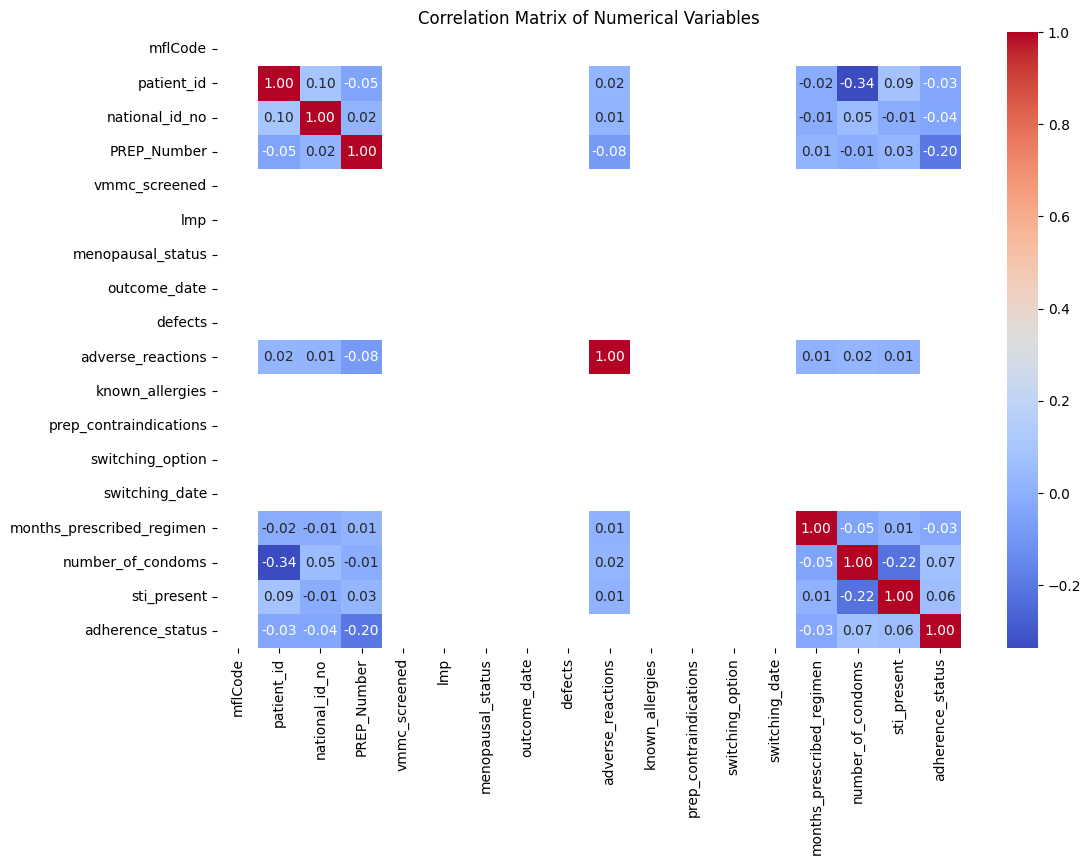

In [142]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12,8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Variables")
plt.show()

Check your PrEP type

In [143]:
df["prep_type"].value_counts(dropna=False)

,count
prep_type,
Daily Oral PrEP,867
NaN,645
Event Driven,43


In [144]:
df["prep_type"].value_counts(normalize=True, dropna=False) * 100

,proportion
prep_type,
Daily Oral PrEP,55.755627
NaN,41.479100
Event Driven,2.765273


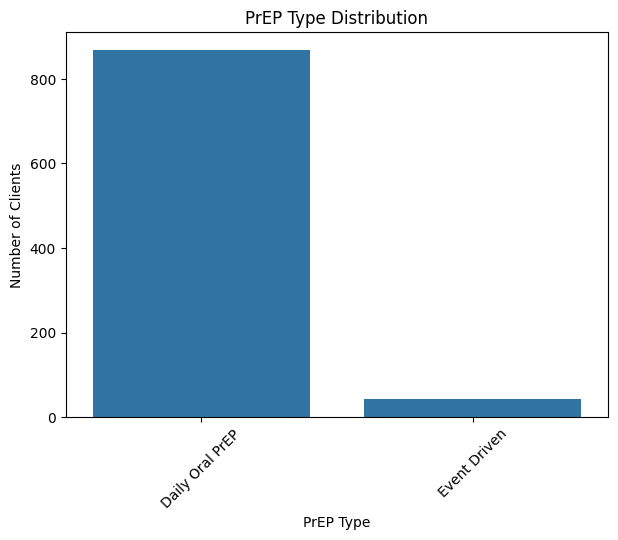

In [145]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="prep_type"
)

plt.title("PrEP Type Distribution")
plt.xlabel("PrEP Type")
plt.ylabel("Number of Clients")

plt.xticks(rotation=45)

plt.show()

Check months prescribed

In [146]:
df["months_prescribed_regimen"].value_counts(dropna=False).sort_index()

,count
months_prescribed_regimen,
1.0,1045
2.0,92
3.0,88
10.0,2
20.0,1
30.0,1
90.0,1
144.0,1
NaN,324


In [147]:
#   Descriptive statistics
df["months_prescribed_regimen"].describe()

,months_prescribed_regimen
count,1231.000000
mean,1.459789
std,4.931874
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,144.000000


In [148]:
df["months_prescribed_clean"] = df[
    "months_prescribed_regimen"
].where(
    df["months_prescribed_regimen"].between(1, 3)
)

In [149]:
df[
    ["months_prescribed_regimen", "months_prescribed_clean"]
].drop_duplicates().sort_values(
    "months_prescribed_regimen"
)

,months_prescribed_regimen,months_prescribed_clean
1,1.0,1.0
9,2.0,2.0
31,3.0,3.0
506,10.0,NaN
1220,20.0,NaN
116,30.0,NaN
1028,90.0,NaN
236,144.0,NaN
0,NaN,NaN


  Check condom df

In [150]:
df["number_of_condoms"].describe()

,number_of_condoms
count,698.000000
mean,20.621777
std,25.947086
min,-3.000000
25%,10.000000
50%,15.000000
75%,20.000000
max,144.000000


Check unusual condom values

In [151]:
df[
    df["number_of_condoms"] > 60
][
    ["number_of_condoms"]
]

,number_of_condoms
3,144.0
4,144.0
5,144.0
6,144.0
8,144.0
15,144.0
16,144.0
18,144.0
21,144.0
23,144.0


In [152]:
df[
    df["number_of_condoms"] > 60
][
    ["number_of_condoms"]
]

,number_of_condoms
3,144.0
4,144.0
5,144.0
6,144.0
8,144.0
15,144.0
16,144.0
18,144.0
21,144.0
23,144.0


Check pregnancy, breastfeeding and family planning

In [153]:
print(df["pregnant"].value_counts(dropna=False))

print(df["breastfeeding"].value_counts(dropna=False))

print(df["fp_status"].value_counts(dropna=False))

pregnant
NaN    788
No     762
Yes      5
Name: count, dtype: int64
breastfeeding
NaN    789
No     745
Yes     21
Name: count, dtype: int64
fp_status
On Family Planning           962
NaN                          577
Not using Family Planning     15
Wants Family Planning          1
Name: count, dtype: int64


  Check clinical variables

In [154]:
clinical_variables = [
    "has_chronic_illness",
    "adverse_reactions",
    "known_allergies",
    "hepatitisB_vaccinated",
    "hepatitisB_treated",
    "hepatitisC_vaccinated",
    "hepatitisC_treated"
]

for col in clinical_variables:
    print("\n", col)
    print(df[col].value_counts(dropna=False))


 has_chronic_illness
has_chronic_illness
NaN    1302
No      253
Name: count, dtype: int64

 adverse_reactions
adverse_reactions
2.0    1329
NaN     213
1.0      13
Name: count, dtype: int64

 known_allergies
known_allergies
NaN    1303
2.0     252
Name: count, dtype: int64

 hepatitisB_vaccinated
hepatitisB_vaccinated
NaN    1077
No      462
Yes      16
Name: count, dtype: int64

 hepatitisB_treated
hepatitisB_treated
NaN    1077
No      462
Yes      16
Name: count, dtype: int64

 hepatitisC_vaccinated
hepatitisC_vaccinated
NaN    1077
No      462
Yes      16
Name: count, dtype: int64

 hepatitisC_treated
hepatitisC_treated
NaN    1077
No      462
Yes      16
Name: count, dtype: int64


Check adherence-support variables

In [155]:
print(
    df["adherence_counselled"].value_counts(
        dropna=False
    )
)

print(
    df["appointment_given"].value_counts(
        dropna=False
    )
)

adherence_counselled
Yes    1183
NaN     202
No      170
Name: count, dtype: int64
appointment_given
Yes    1337
NaN     202
No       16
Name: count, dtype: int64


Avoid df leakage

Don't use variables that essentially reveal the adherence outcome.

For example, avoid:

In [156]:
leakage_variables = [
    "poor_adherence_reasons",
    "other_poor_adherence_reasons",
    "discontinue_reason",
    "date_discontinued",
    "last_prep_dose_date"
]

In [157]:
df = df.drop(
    columns=[
        col for col in leakage_variables
        if col in df.columns
    ]
)

  Select the final predictors

These are the variables I'd start with:

In [158]:
predictors = [
    "age",
    "Gender",
    "population_type",
    "key_population_type",
    "patient_type",
    "referral_entry_point",

    "prep_type",
    "regimen_prescribed",
    "months_prescribed_clean",

    "condoms_issued",
    "number_of_condoms",

    "sti_present",

    "pregnant",
    "wanted_pregnancy",
    "breastfeeding",
    "fp_status",

    "has_chronic_illness",
    "adverse_reactions",
    "known_allergies",

    "hepatitisB_vaccinated",
    "hepatitisB_treated",
    "hepatitisC_vaccinated",
    "hepatitisC_treated",

    "adherence_counselled",
    "appointment_given"
]

In [159]:
predictors = [
    col for col in predictors
    if col in df.columns
]

Create X and Y variables

In [160]:
X = df[predictors].copy()

y = df["adherence_status"]

In [161]:
y.value_counts()

,count
adherence_status,
0.0,161
1.0,19


Separate numerical and categorical variables

In [162]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numeric_features = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

In [163]:
print("Categorical:")
print(categorical_features)

print("\nNumerical:")
print(numeric_features)

Categorical:
['Gender', 'population_type', 'key_population_type', 'patient_type', 'referral_entry_point', 'prep_type', 'regimen_prescribed', 'condoms_issued', 'pregnant', 'wanted_pregnancy', 'breastfeeding', 'fp_status', 'has_chronic_illness', 'hepatitisB_vaccinated', 'hepatitisB_treated', 'hepatitisC_vaccinated', 'hepatitisC_treated', 'adherence_counselled', 'appointment_given']

Numerical:
['months_prescribed_clean', 'number_of_condoms', 'sti_present', 'adverse_reactions', 'known_allergies']


Build preprocessing pipeline

Numerical variables:

In [164]:
numeric_transformer = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "scaler",
        StandardScaler()
    )
])

In [165]:
# Categorical variables
categorical_transformer = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="most_frequent"
        )
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])

In [166]:
# Combine them
preprocessor = ColumnTransformer([
    (
        "num",
        numeric_transformer,
        numeric_features
    ),
    (
        "cat",
        categorical_transformer,
        categorical_features
    )
])


Logistic Regression

Create the df:

In [167]:
logistic_df = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "df",
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            solver="liblinear"
        )
    )
])

Random Forest

In [168]:
from sklearn.ensemble import RandomForestClassifier

random_forest_df = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "df",
        RandomForestClassifier(
            n_estimators=500,
            random_state=42,
            class_weight="balanced",
            min_samples_leaf=3,
            n_jobs=-1
        )
    )
])

Gradient Boosting

In [169]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_df = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "df",
        GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=2,
            random_state=42
        )
    )
])

Stratified cross-validation

Because we only have 19 suboptimal cases, don't randomly split without preserving the classes.

In [170]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

Evaluate Logistic Regression

In [171]:
from sklearn.model_selection import cross_validate

# Ensure X and y contain only the records with known adherence outcomes
y_clean = y.dropna().astype(int)
X_clean = X.loc[y_clean.index]

logistic_scores = cross_validate(
    logistic_df,
    X_clean,
    y_clean,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ]
)

# Print scores to verify it works
for metric, scores in logistic_scores.items():
    print(f"{metric}: {scores.mean():.4f} (+/- {scores.std() * 2:.4f})")

fit_time: 0.0184 (+/- 0.0017)
score_time: 0.0308 (+/- 0.0031)
test_accuracy: 0.7222 (+/- 0.0786)
test_precision: 0.1438 (+/- 0.1704)
test_recall: 0.4167 (+/- 0.6667)
test_f1: 0.2106 (+/- 0.2700)
test_roc_auc: 0.7168 (+/- 0.3015)


In [172]:
print(
    "Accuracy:",
    logistic_scores["test_accuracy"].mean()
)

print(
    "Precision:",
    logistic_scores["test_precision"].mean()
)

print(
    "Recall:",
    logistic_scores["test_recall"].mean()
)

print(
    "F1:",
    logistic_scores["test_f1"].mean()
)

print(
    "ROC-AUC:",
    logistic_scores["test_roc_auc"].mean()
)

Accuracy: 0.7222222222222221
Precision: 0.14380952380952378
Recall: 0.41666666666666663
F1: 0.21057416267942583
ROC-AUC: 0.7167613636363637


Evaluate Random Forest

In [173]:
rf_scores = cross_validate(
    random_forest_df,
    X_clean,
    y_clean,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ]
)

# Print scores to verify it works
for metric, scores in rf_scores.items():
    print(f"{metric}: {scores.mean():.4f} (+/- {scores.std() * 2:.4f})")

fit_time: 1.2294 (+/- 0.3220)
score_time: 0.2558 (+/- 0.0247)
test_accuracy: 0.7500 (+/- 0.0000)
test_precision: 0.2550 (+/- 0.0649)
test_recall: 0.7500 (+/- 0.4472)
test_f1: 0.3772 (+/- 0.1247)
test_roc_auc: 0.8097 (+/- 0.1737)


In [174]:
print(
    "Accuracy:",
    rf_scores["test_accuracy"].mean()
)

print(
    "Precision:",
    rf_scores["test_precision"].mean()
)

print(
    "Recall:",
    rf_scores["test_recall"].mean()
)

print(
    "F1:",
    rf_scores["test_f1"].mean()
)

print(
    "ROC-AUC:",
    rf_scores["test_roc_auc"].mean()
)

Accuracy: 0.75
Precision: 0.254972804972805
Recall: 0.75
F1: 0.37719457013574664
ROC-AUC: 0.8096748737373737


Compare the dfs

In [175]:
results = pd.DataFrame({
    "df": [
        "Logistic Regression",
        "Random Forest"
    ],

    "Accuracy": [
        logistic_scores["test_accuracy"].mean(),
        rf_scores["test_accuracy"].mean()
    ],

    "Precision": [
        logistic_scores["test_precision"].mean(),
        rf_scores["test_precision"].mean()
    ],

    "Recall": [
        logistic_scores["test_recall"].mean(),
        rf_scores["test_recall"].mean()
    ],

    "F1": [
        logistic_scores["test_f1"].mean(),
        rf_scores["test_f1"].mean()
    ],

    "ROC-AUC": [
        logistic_scores["test_roc_auc"].mean(),
        rf_scores["test_roc_auc"].mean()
    ]
})

results.round(3)

,df,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.722,0.144,0.417,0.211,0.717
1,Random Forest,0.750,0.255,0.750,0.377,0.810


Train the final Random Forest



In [176]:
random_forest_df.fit(X_clean, y_clean)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['months_prescribed_clean',
                                                   'number_of_condoms',
                                                   'sti_present',
                                                   'adverse_reactions',
                                                   'known_allergies']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequ...
                                                   'condoms_issued', 'pregnant',
                                                   'wanted_pregnancy',
                                                   'breastfeeding', 'fp_status',
                                                   'has_chronic_illness',
                                                   'hepatitisB_vaccinated',
                                                   'hepatitisB_treated',
                                                   'hepatitisC_vaccinated',
                                                   'hepatitisC_treated',
                                                   'adherence_counselled',
                                                   'appointment_given'])])),
                ('df',
                 RandomForestClassifier(class_weight='balanced',
                                        min_samples_leaf=3, n_estimators=500,
                                        n_jobs=-1, random_state=42))])

Get feature importance

Because we have preprocessing and one-hot encoding, we first need the transformed feature names.

In [177]:
preprocessor_fitted = (
    random_forest_df
    .named_steps["preprocessor"]
)

rf_fitted = (
    random_forest_df
    .named_steps["df"]
)

In [178]:
feature_names = (
    preprocessor_fitted
    .get_feature_names_out()
)

In [179]:
importance = rf_fitted.feature_importances_

In [180]:
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

/tmp/ipykernel_3199/591841679.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


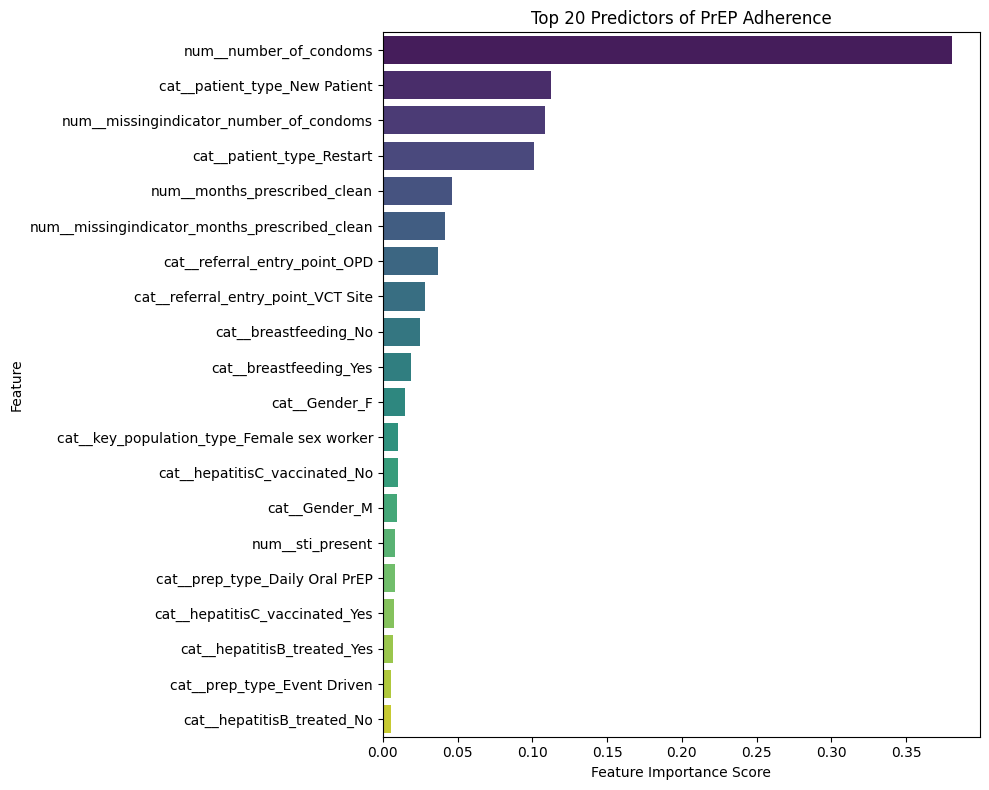

In [181]:
import matplotlib.pyplot as plt
import seaborn as sns

top_20_features = feature_importance.head(20)

plt.figure(figsize=(10, 8))
sns.barplot(
    data=top_20_features,
    x="Importance",
    y="Feature",
    palette="viridis"
)

plt.title("Top 20 Predictors of PrEP Adherence")
plt.xlabel("Feature Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [182]:
feature_importance.head(20)

,Feature,Importance
1,num__number_of_condoms,0.380308
14,cat__patient_type_New Patient,0.112306
6,num__missingindicator_number_of_condoms,0.108394
15,cat__patient_type_Restart,0.101199
0,num__months_prescribed_clean,0.046402
5,num__missingindicator_months_prescribed_clean,0.041524
18,cat__referral_entry_point_OPD,0.036789
19,cat__referral_entry_point_VCT Site,0.028441
29,cat__breastfeeding_No,0.024634
30,cat__breastfeeding_Yes,0.018978


Plot feature importance

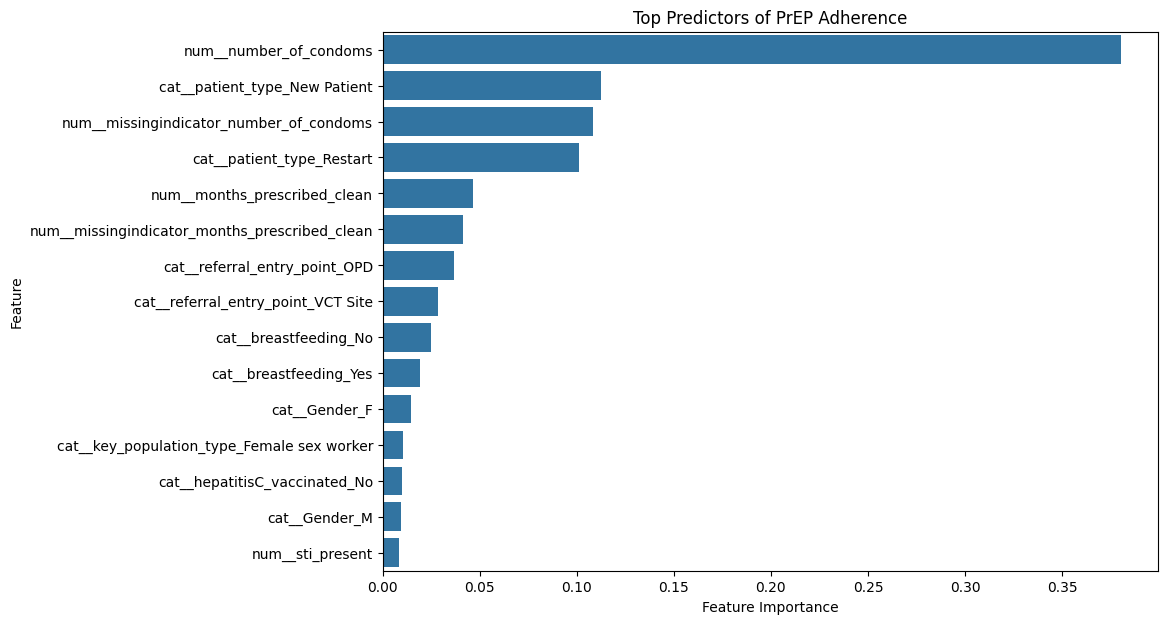

In [183]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title(
    "Top Predictors of PrEP Adherence"
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.show()

Logistic regression coefficients

For interpretation, Logistic Regression is useful.

Fit it:

In [184]:
logistic_df.fit(X_clean, y_clean)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['months_prescribed_clean',
                                                   'number_of_condoms',
                                                   'sti_present',
                                                   'adverse_reactions',
                                                   'known_allergies']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequ...
                                                   'prep_type',
                                                   'regimen_prescribed',
                                                   'condoms_issued', 'pregnant',
                                                   'wanted_pregnancy',
                                                   'breastfeeding', 'fp_status',
                                                   'has_chronic_illness',
                                                   'hepatitisB_vaccinated',
                                                   'hepatitisB_treated',
                                                   'hepatitisC_vaccinated',
                                                   'hepatitisC_treated',
                                                   'adherence_counselled',
                                                   'appointment_given'])])),
                ('df',
                 LogisticRegression(class_weight='balanced', max_iter=3000,
                                    solver='liblinear'))])

In [185]:
# get co-efficients
logistic_preprocessor = (
    logistic_df
    .named_steps["preprocessor"]
)

logistic_fitted = (
    logistic_df
    .named_steps["df"]
)

logistic_features = (
    logistic_preprocessor
    .get_feature_names_out()
)

coefficients = logistic_fitted.coef_[0]


In [190]:
# Create tables
coef_df = pd.dfFrame({
    "Feature": logistic_features,
    "Coefficient": coefficients
})

AttributeError: module 'pandas' has no attribute 'dfFrame'

In [191]:
#Sort
coef_df["Absolute_Coefficient"] = (
    coef_df["Coefficient"].abs()
)

coef_df = coef_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

coef_df.head(20)

,Feature,Coefficient,Absolute_Coefficient
6,num__missingindicator_number_of_condoms,-1.074039,1.074039
30,cat__breastfeeding_Yes,-0.847765,0.847765
15,cat__patient_type_Restart,0.818049,0.818049
0,num__months_prescribed_clean,-0.802074,0.802074
14,cat__patient_type_New Patient,-0.722997,0.722997
29,cat__breastfeeding_No,0.658277,0.658277
8,cat__Gender_M,-0.525892,0.525892
1,num__number_of_condoms,0.459442,0.459442
21,cat__prep_type_Event Driven,-0.400940,0.400940
13,cat__key_population_type_Men who have sex with...,-0.391031,0.391031


  Odds  Ratio

In [192]:
import pandas as pd

# Recreate the coefficients DataFrame correcting the previous typo
coef_df = pd.DataFrame({
    "Feature": logistic_features,
    "Coefficient": coefficients
})

# Calculate absolute values and sort
coef_df["Absolute_Coefficient"] = (
    coef_df["Coefficient"].abs()
)

coef_df = coef_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

coef_df.head(20)

,Feature,Coefficient,Absolute_Coefficient
6,num__missingindicator_number_of_condoms,-1.074039,1.074039
30,cat__breastfeeding_Yes,-0.847765,0.847765
15,cat__patient_type_Restart,0.818049,0.818049
0,num__months_prescribed_clean,-0.802074,0.802074
14,cat__patient_type_New Patient,-0.722997,0.722997
29,cat__breastfeeding_No,0.658277,0.658277
8,cat__Gender_M,-0.525892,0.525892
1,num__number_of_condoms,0.459442,0.459442
21,cat__prep_type_Event Driven,-0.400940,0.400940
13,cat__key_population_type_Men who have sex with...,-0.391031,0.391031


Interpretation:

Odds ratio > 1 → associated with higher odds of suboptimal adherence.
Odds ratio < 1 → associated with lower odds of suboptimal adherence.
Odds ratio ≈ 1 → little association.

Confusion matrix

In [193]:
from sklearn.model_selection import cross_val_predict

rf_predictions = cross_val_predict(
    random_forest_df,
    X_clean,
    y_clean,
    cv=cv,
    method="predict"
)

In [194]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_clean,
    rf_predictions
)

print(cm)

[[121  40]
 [  5  14]]


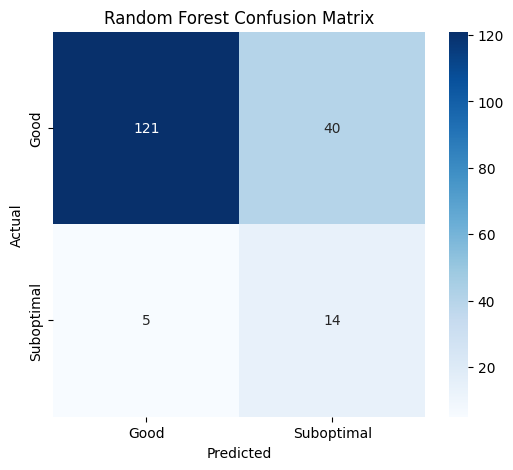

In [195]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Good",
        "Suboptimal"
    ],
    yticklabels=[
        "Good",
        "Suboptimal"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

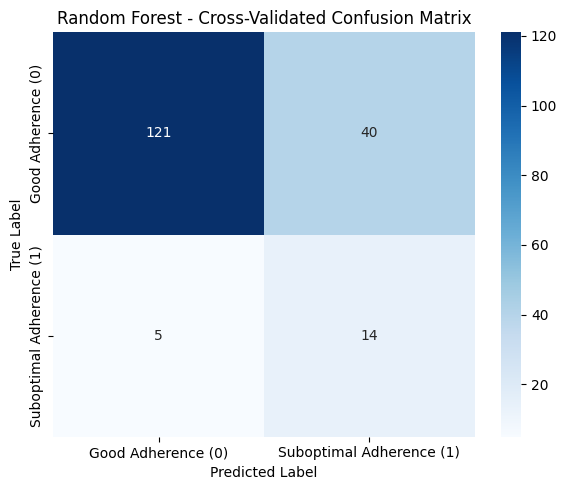

In [196]:
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict
import seaborn as sns
import matplotlib.pyplot as plt

# Ensure rf_predictions are generated via cross-validation
rf_predictions = cross_val_predict(
    random_forest_df,
    X_clean,
    y_clean,
    cv=cv,
    method="predict"
)

# Calculate the confusion matrix
cm = confusion_matrix(y_clean, rf_predictions)

# Plot the confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Good Adherence (0)", "Suboptimal Adherence (1)"],
    yticklabels=["Good Adherence (0)", "Suboptimal Adherence (1)"]
)
plt.title("Random Forest - Cross-Validated Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

Confusion Matrix Breakdown

True Negatives (Top-Left: 121): The model correctly predicted 121 patients as having Good Adherence (0).

False Positives (Top-Right: 40): The model predicted 40 patients would have suboptimal adherence, but they actually had Good Adherence (0).

False Negatives (Bottom-Left: 5): The model predicted 5 patients would have good adherence, but they actually had Suboptimal Adherence (1). This represents the missed cases

True Positives (Bottom-Right: 14): The model correctly identified 14 patients who actually had Suboptimal Adherence (1).

Clinical Translation

High Identification Rate (Recall = 74%): By identifying 14 out of 19 patients with suboptimal adherence, the clinic can proactively reach out to almost three-quarters of the patients at risk of discontinuation or poor adherence before it's too late.

Manageable False Alarms: Out of 54 total positive predictions, 40 were false alarms. While this results in a lower precision (~25.5%), in a clinical prevention context (like PrEP), sending a friendly check-in or counselor call to a compliant patient is far less costly than completely missing a patient who is struggling to stay on their medication

Classification report

In [197]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_clean,
        rf_predictions,
        target_names=[
            "Good",
            "Suboptimal"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

        Good       0.96      0.75      0.84       161
  Suboptimal       0.26      0.74      0.38        19

    accuracy                           0.75       180
   macro avg       0.61      0.74      0.61       180
weighted avg       0.89      0.75      0.79       180



In [198]:
rf_probabilities = cross_val_predict(
    random_forest_df,
    X_clean,
    y_clean,
    cv=cv,
    method="predict_proba"
)[:, 1]

In [199]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(
    y_clean,
    rf_probabilities
)

auc = roc_auc_score(
    y_clean,
    rf_probabilities
)

  Plot  ROC-CURVE

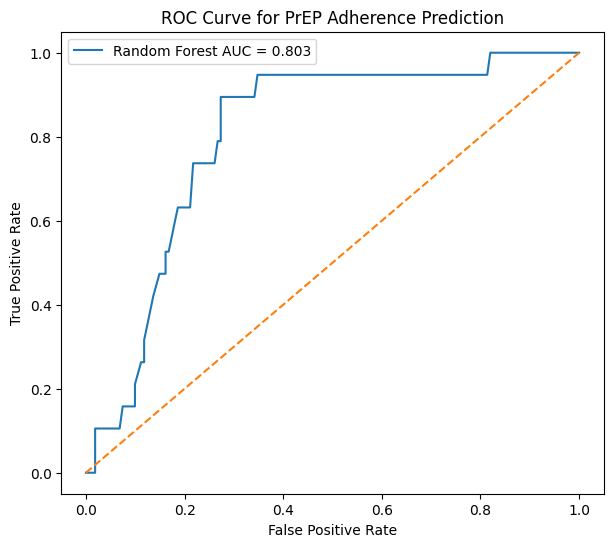

In [200]:
plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest AUC = {auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve for PrEP Adherence Prediction"
)

plt.legend()

plt.show()

Save the final clean dfset

In [201]:
df_df.to_csv(
    "prep_adherence_final_clean_dfset.csv",
    index=False
)

Save feature importance

In [202]:
feature_importance.to_csv(
    "prep_adherence_feature_importance.csv",
    index=False
)

Save df comparison

In [203]:
results.to_csv(
    "prep_adherence_df_comparison.csv",
    index=False
)